# Mirror-circuit benchmarking

A mirror circuit runs random layers and then their inverse, so the ideal output is all zeros whatever the layers. The
probability of getting all zeros back, as the depth grows, decays roughly exponentially; the decay rate is an effective
error per layer that summarises a device for this kind of circuit.

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': 'c88add07efb8:7:9e791f',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. A mirror circuit returns to zero

Ideally every shot reads 0000; with noise some do not.

In [2]:
prog = mirror(4, 4, seed=3)
for noise in (None, True):
    r = run("iqm_emerald", prog, shots=20000, noise=noise, routing=True)
    print("device noise" if noise else "ideal       ", "P(0000) =", round(success(r, ["0000"]), 4))

ideal        P(0000) = 1.0
device noise P(0000) = 0.7884


## 2. Decay with depth

Success against the number of random layers, averaged over three random circuits per depth.

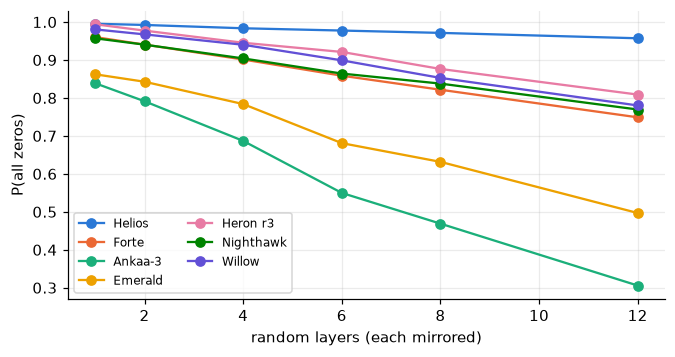

In [3]:
depths = [1, 2, 4, 6, 8, 12]
curves = {}
for b in ALL_BACKENDS:
    curves[b] = [np.mean([success(run(b, mirror(4, d, seed=s), shots=4000, noise=True, routing=True), ["0000"])
                          for s in (1, 2, 3)]) for d in depths]
fig, ax = plt.subplots(figsize=(7, 3.4))
for b, ys in curves.items():
    ax.plot(depths, ys, "o-", color=COLORS[b], label=NAMES[b])
ax.set_xlabel("random layers (each mirrored)"); ax.set_ylabel("P(all zeros)"); ax.legend(ncols=2, fontsize=8); plt.show()

## 3. An effective error per layer

Fitting A·pᵈ to each curve gives 1 − p, an effective error per mirrored layer.

In [4]:
rows = []
for b, ys in curves.items():
    slope, intercept = np.polyfit(depths, np.log(np.clip(ys, 1e-6, None)), 1)
    rows.append({"twin": NAMES[b], "error per layer (1 - p)": round(1 - np.exp(slope), 4), "A": round(np.exp(intercept), 3)})
pd.DataFrame(rows).set_index("twin").sort_values("error per layer (1 - p)")

,error per layer (1 - p),A
twin,,
Helios,0.0035,0.999
Heron r3,0.0185,1.018
Nighthawk,0.0196,0.977
Willow,0.0209,1.012
Forte,0.0224,0.984
Emerald,0.0497,0.932
Ankaa-3,0.0883,0.955


## 4. Routing changes the score

On the lattices, routing adds SWAPs, and mirrored layers of random pairs need many. The same benchmark at 6 qubits shows the extra cost of connectivity.

In [5]:
rows = []
for b in ALL_BACKENDS:
    r = run(b, mirror(6, 4, seed=1), shots=4000, noise=True, routing=True)
    rows.append({"twin": NAMES[b], "SWAPs": (r["compilation"]["routing"] or {}).get("swaps_inserted", 0),
                 "native 2Q gates": r["compilation"]["native_two_qubit_count"], "P(000000)": round(success(r, ["000000"]), 4)})
pd.DataFrame(rows).set_index("twin")

,SWAPs,native 2Q gates,P(000000)
twin,,,
Helios,0,24,0.9765
Forte,0,24,0.8395
Ankaa-3,4,36,0.4575
Emerald,4,36,0.6142
Heron r3,10,54,0.8952
Nighthawk,4,36,0.8333
Willow,4,36,0.8265


## Takeaways

- Mirror circuits give a scalable, model-free benchmark: the ideal answer is always all zeros.
- The effective error per layer folds gate errors, idle noise and routing into one comparable number.